# Developmental Project - Supplementary - Subject exclusion feature distribution
- Determining whether final sample included in study (N=6171) has subjects from the full ABCD sample who have been excluded not at random (skewed by age, sex, pubertal stage)

https://nda.nih.gov/study.html?id=2313

## Load Packages

In [1]:
# General
import os
import sys
import numpy as np
import pandas as pd
import csv
import math
from math import isnan
import statistics
import pickle
from collections import Counter

# Computing / Analyses
import scipy.io  # loadmat
import fnmatch # for comparing patterns of syntax
from scipy import stats
import sklearn 
from brainstat.stats.terms import FixedEffect
from brainstat.stats.SLM import SLM
from statsmodels.stats.multitest import fdrcorrection # does not yield exactly the same FDR correction as R but the same up to 14th decimal place so good enough
import statsmodels.regression.mixed_linear_model as sm
from sklearn.preprocessing import scale

# Visualisation
import matplotlib.pyplot as plt 
import seaborn as sns
import vtk
from IPython.display import display
import matplotlib.collections as clt
#import ptitprince as pt  # commented out because clashing dependencies with seaborn

# Neuroimaging
import nibabel as nib
import nilearn
from brainstat.datasets import fetch_parcellation
from enigmatoolbox.permutation_testing import spin_test, shuf_test

# Gradients
import brainspace
from brainspace.datasets import load_parcellation, load_conte69
from brainspace.plotting import plot_hemispheres
from brainspace.gradient import GradientMaps
from brainspace.utils.parcellation import map_to_labels

## Define directories

In [2]:
codedir = os.path.abspath('')  # obtain current direction from which script is runnning

datadir_local = '/data/p_02667/development/data/'
datadir_local_pds_cleaned = '/data/p_02667/development/data/pds_cleaned/'
datadir = '/data/pt_02667/data/ABCD/'

resdir = '/data/p_02667/development/results/'
resdir_fig = '/data/p_02667/development/results/figures/'

## Load final sample (puberty cleaned)

In [21]:
abcd_demo_baseline_clean = pd.read_csv(datadir_local_pds_cleaned+'abcd_demo_baseline_clean.csv')
abcd_demo_fu2y_clean = pd.read_csv(datadir_local_pds_cleaned+'abcd_demo_fu2y_clean.csv')
abcd_demo_fu4y_clean = pd.read_csv(datadir_local_pds_cleaned+'abcd_demo_fu4y_clean.csv')

In [7]:
abcd_demo_full_clean = pd.read_csv(datadir_local_pds_cleaned+'abcd_demo_full_clean.csv')
abcd_demo_full_clean

,src_subject_id_fmt,age_baseline_yrs,sex,edu_parent,eventname,site_id,family_id,age_months,pds_y_cat,pds_p_cat,pds_y_score,pds_p_score,BMIz,tot_SA,cbcl_tot,cbcl_int,cbcl_ext,fam_conflict_y
0,sub-NDARINV003RTV85,10.0,F,13.0,baseline_year_1_arm_1,site06,8781.0,131.0,3.0,3.0,1.6,2.4,0.961662,188827.953554,4.0,1.0,1.0,3.0
1,sub-NDARINV007W6H7B,10.0,M,19.0,baseline_year_1_arm_1,site22,4722.0,126.0,2.0,1.0,1.5,1.0,0.550824,233329.288961,23.0,8.0,2.0,0.0
2,sub-NDARINV00J52GPG,9.0,M,21.0,baseline_year_1_arm_1,site17,4151.0,110.0,2.0,2.0,1.4,1.6,1.129072,201853.751338,11.0,0.0,1.0,0.0
3,sub-NDARINV00LH735Y,9.0,M,13.0,baseline_year_1_arm_1,site03,6069.0,109.0,1.0,1.0,1.0,1.4,1.570677,204865.644678,8.0,4.0,2.0,0.0
4,sub-NDARINV00NPMHND,9.0,F,18.0,baseline_year_1_arm_1,site17,4152.0,118.0,2.0,3.0,1.5,1.8,0.363954,212433.396427,42.0,23.0,3.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6166,sub-NDARINVZYC44GB8,10.0,M,21.0,4_year_follow_up_y_arm_1,site16,1840.0,179.0,4.0,4.0,3.0,3.0,-0.503814,206655.702684,0.0,0.0,0.0,0.0
6167,sub-NDARINVZYRTFYRP,9.0,M,13.0,4_year_follow_up_y_arm_1,site10,10925.0,164.0,1.0,3.0,1.6,2.6,-0.428811,173346.170313,20.0,4.0,5.0,1.0
6168,sub-NDARINVZZ1MNPK5,10.0,F,20.0,4_year_follow_up_y_arm_1,site08,7031.0,175.0,5.0,4.0,3.6,3.6,-0.500384,171459.001848,20.0,13.0,2.0,0.0
6169,sub-NDARINVZZ81LEEV,9.0,M,15.0,4_year_follow_up_y_arm_1,site11,8433.0,157.0,2.0,2.0,1.2,1.8,-1.408592,202083.016847,6.0,3.0,0.0,0.0


## Load subject MRI info/QC data 

In [8]:
mri_qc_incl = pd.read_csv(datadir+'abcd-data-release-5.1/core/imaging/mri_y_qc_incl.csv')  

In [9]:
mri_qc_incl

,src_subject_id,eventname,imgincl_t1w_include,imgincl_t2w_include,imgincl_dmri_include,imgincl_rsfmri_include,imgincl_mid_include,imgincl_nback_include,imgincl_sst_include
0,NDAR_INV003RTV85,baseline_year_1_arm_1,1,1,1,1,1,1,1
1,NDAR_INV005V6D2C,baseline_year_1_arm_1,1,1,1,0,1,0,0
2,NDAR_INV007W6H7B,baseline_year_1_arm_1,1,1,0,1,1,1,1
3,NDAR_INV00BD7VDC,baseline_year_1_arm_1,1,1,1,1,1,1,1
4,NDAR_INV00CY2MDM,2_year_follow_up_y_arm_1,1,1,1,1,1,1,1
...,...,...,...,...,...,...,...,...,...
22934,NDAR_INVZZZNB0XC,4_year_follow_up_y_arm_1,1,1,1,1,1,1,1
22935,NDAR_INVZZZNB0XC,baseline_year_1_arm_1,1,1,1,1,1,0,1
22936,NDAR_INVZZZP87KR,2_year_follow_up_y_arm_1,1,1,1,1,0,0,1
22937,NDAR_INVZZZP87KR,4_year_follow_up_y_arm_1,1,1,1,1,1,1,0


### Full ABCD sample

In [15]:
sub_full_sample_abcd_baseline = mri_qc_incl[mri_qc_incl['eventname']=='baseline_year_1_arm_1'].src_subject_id.tolist()
len(sub_full_sample_abcd_baseline)

11771

In [16]:
sub_full_sample_abcd_baseline_relabelled = []

for sub_id in sub_full_sample_abcd_baseline:
    sub_full_sample_abcd_baseline_relabelled.append(sub_id.replace("NDAR_", "sub-NDAR"))

# Making list of subjects with validated QC rsfmri data at each timepoint to maximize sample

T1w and rsfMRI (REQUIRED for running fmriprep/getting fmriprep output)

In [17]:
eventnames = {'baseline_year_1_arm_1': [], '2_year_follow_up_y_arm_1': [], '4_year_follow_up_y_arm_1': []}


# iterate over each individual subject ID (list yielded from baseline sample)
for sub in sub_full_sample_abcd_baseline:

    for eventname in eventnames.keys():

        # Subset the relevant row(s) for that subject and event
        row = mri_qc_incl[(mri_qc_incl['src_subject_id'] == sub) & (mri_qc_incl['eventname'] == eventname)]

        if not row.empty:
            
            # if data passes QC for both T1w and rfMRI for that timepoint (ie score == 2) - assuming there is just one row (and therefore doing iloc[0] otherwise bool does not take series
            if row.iloc[0].imgincl_t1w_include + row.iloc[0].imgincl_rsfmri_include == 2:
                eventnames[eventname].append(sub)


        
# storing subjects that have QC'd rsfmri data by timepoint in their own list
sub_baseline_qc_val = eventnames['baseline_year_1_arm_1']
sub_fu2y_qc_val = eventnames['2_year_follow_up_y_arm_1']
sub_fu4y_qc_val = eventnames['4_year_follow_up_y_arm_1']        

In [18]:
print(f"Subjects with QC'd T1w and rsfMRI at baseline: {len(sub_baseline_qc_val)}")
print(f"Subjects with QC'd T1w and rsfMRI at fu2y: {len(sub_fu2y_qc_val)}")
print(f"Subjects with QC'd T1w and rsfMRI at fu4y: {len(sub_fu4y_qc_val)}")

Subjects with QC'd T1w and rsfMRI at baseline: 9374
Subjects with QC'd T1w and rsfMRI at fu2y: 6931
Subjects with QC'd T1w and rsfMRI at fu4y: 2796


In [19]:
# Relabelling subject id lists

# Baseline
sub_baseline_qc_val_relabelled = []

for sub_id in sub_baseline_qc_val:
    sub_baseline_qc_val_relabelled.append(sub_id.replace("NDAR_", "sub-NDAR"))


# 2y Follow Up
sub_fu2y_qc_val_relabelled = []

for sub_id in sub_fu2y_qc_val:
    sub_fu2y_qc_val_relabelled.append(sub_id.replace("NDAR_", "sub-NDAR"))


# 4y Follow Up
sub_fu4y_qc_val_relabelled = []

for sub_id in sub_fu4y_qc_val:
    sub_fu4y_qc_val_relabelled.append(sub_id.replace("NDAR_", "sub-NDAR"))

# Making Demographics dataframe for all

In [23]:
## Load dataframes 
# Demographics (parental report)
abcd_p_demo = pd.read_csv(datadir+'abcd-data-release-5.1/core/abcd-general/abcd_p_demo.csv')

# longitudinal tracking
abcd_y_lt = pd.read_csv(datadir+'abcd-data-release-5.1/core/abcd-general/abcd_y_lt.csv')

/tmp/ipykernel_161943/1109638894.py:6: DtypeWarning: Columns (4) have mixed types. Specify dtype option on import or set low_memory=False.
  abcd_y_lt = pd.read_csv(datadir+'abcd-data-release-5.1/core/abcd-general/abcd_y_lt.csv')


In [25]:
## keeping full sample

# note: here length is larger than 4938 (3x1646) because there are also the non-imaging timepoints (1y & 3y followup data)
# here we don't have full 5x1646 data (maybe missing data from sessions 1y & 3y in some subjects) but note the NaNs: demographics probably only filled at baseline anyway

## take one entry per subject because we only need the information once
abcd_p_demo_baseline =  abcd_p_demo[abcd_p_demo['eventname'] == 'baseline_year_1_arm_1']

# taking only a subset of df with relevant columns(*** WILL LATER ADD OTHERS LIKE RACE AND SES - should also add site (AND GENDER CHILD REPORT FROM OTHER CSV FILE) IF THEY CAN BE SIMPLY ADDED HERE, OR BELOW IF NEED TO CLEAN ***)
# not taking the "baseline" column as it's in the name of the dataframe (and information that won't change (ie age at baseline, sex)
abcd_demo_clean_baseline = abcd_p_demo_baseline[['src_subject_id', 'demo_brthdat_v2', 'demo_prnt_ed_v2', 'demo_prtnr_ed_v2']]


### Cleaning variables

# renaming some variables
abcd_demo_clean_baseline = abcd_demo_clean_baseline.rename(columns={"demo_brthdat_v2": "age_baseline_yrs", "demo_prnt_ed_v2": "edu_parent_self", "demo_prtnr_ed_v2": "edu_parent_partner"})


## SEX: coding female and male
# demo_sex_v2: 'What sex was the child assigned at birth, on the original birth certificate?' -> 1 = Male; 2 = Female; 3 = Intersex-Male; 4 = Intersex-Female; 999 = Don't know; 777 = Refuse to answer 

sex_letter = []

for sex_num in abcd_p_demo_baseline.demo_sex_v2:
    
    if sex_num == 1:
        sex_letter.append('M')
        
    elif sex_num == 2:
        sex_letter.append('F')
        
    elif sex_num == 3:
        sex_letter.append('Intersex-M')
        
    elif sex_num == 4:
        sex_letter.append('Intersex-F')
        
    else:  # would represent "don't know" and "refuse to answer"
        sex_letter.append('n/a') 

abcd_demo_clean_baseline['sex'] = sex_letter


## Making a combined parental education column (highest of the two)

# Recode 777 / 999 to NaN
abcd_demo_clean_baseline[["edu_parent_self", "edu_parent_partner"]] = (abcd_demo_clean_baseline[["edu_parent_self", "edu_parent_partner"]].replace([777.0, 999.0], np.nan))

# Create edu_parent as the max across the two columns (ignores NaNs by default)
abcd_demo_clean_baseline["edu_parent"] = (abcd_demo_clean_baseline[["edu_parent_self", "edu_parent_partner"]].max(axis=1))

## reset index
abcd_demo_clean_baseline.reset_index(drop=True)

,src_subject_id,age_baseline_yrs,edu_parent_self,edu_parent_partner,sex,edu_parent
0,NDAR_INV003RTV85,10.0,13.0,13.0,F,13.0
1,NDAR_INV005V6D2C,10.0,6.0,NaN,F,6.0
2,NDAR_INV007W6H7B,10.0,19.0,18.0,M,19.0
3,NDAR_INV00BD7VDC,9.0,20.0,20.0,M,20.0
4,NDAR_INV00CY2MDM,10.0,15.0,NaN,M,15.0
...,...,...,...,...,...,...
11863,NDAR_INVZZNX6W2P,10.0,18.0,18.0,M,18.0
11864,NDAR_INVZZPKBDAC,9.0,19.0,18.0,F,19.0
11865,NDAR_INVZZZ2ALR6,10.0,21.0,21.0,F,21.0
11866,NDAR_INVZZZNB0XC,9.0,19.0,13.0,F,19.0


In [26]:
### Family and site information

# take a subset of the dataframe - i.e. only the events we need: baseline, 2y and 4y follow up
abcd_y_lt_full = abcd_y_lt[abcd_y_lt['eventname'].isin(['baseline_year_1_arm_1', '2_year_follow_up_y_arm_1', '4_year_follow_up_y_arm_1'])]

# taking only a subset of df with relevant columns
abcd_y_lt_clean = abcd_y_lt_full[['src_subject_id', 'eventname', 'site_id_l', 'rel_family_id', 'interview_age']]


# Given that family ID info is only available at baseline, we need to populate family id for other timepoints as well

# Step 1: Extract rel_family_id from baseline only
baseline_rel_fam = abcd_y_lt_clean[abcd_y_lt_clean['eventname'] == 'baseline_year_1_arm_1'][['src_subject_id', 'rel_family_id']]

# Step 2: Merge rel_family_id from baseline into the full dataframe using src_subject_id as key and rename rel_family_id to re_family_id
abcd_y_lt_clean = (
    abcd_y_lt_clean
    .drop(columns='rel_family_id')
    .merge(baseline_rel_fam, on='src_subject_id', how='left')
    .rename(columns={'rel_family_id': 'family_id'})
)

In [27]:
abcd_y_lt_clean

,src_subject_id,eventname,site_id_l,interview_age,family_id
0,NDAR_INV003RTV85,baseline_year_1_arm_1,site06,131.0,8781.0
1,NDAR_INV003RTV85,2_year_follow_up_y_arm_1,site06,157.0,8781.0
2,NDAR_INV005V6D2C,baseline_year_1_arm_1,site10,121.0,10210.0
3,NDAR_INV005V6D2C,2_year_follow_up_y_arm_1,site10,148.0,10210.0
4,NDAR_INV007W6H7B,baseline_year_1_arm_1,site22,126.0,4722.0
...,...,...,...,...,...
27590,NDAR_INVZZZNB0XC,baseline_year_1_arm_1,site03,108.0,6676.0
27591,NDAR_INVZZZNB0XC,4_year_follow_up_y_arm_1,site03,157.0,6676.0
27592,NDAR_INVZZZP87KR,baseline_year_1_arm_1,site19,126.0,7569.0
27593,NDAR_INVZZZP87KR,2_year_follow_up_y_arm_1,site19,150.0,7569.0


## Including puberty

https://data-dict.abcdstudy.org/

Pubertal Development Scale (PDS)
Petersen, A. C., Crockett, L., et al. (1988) A self-report measure of pubertal status: Reliability, validity, and initial norms. J Youth Adolesc 17(2): 117-133.

In [28]:
# Load dataframes

# child report
ph_y_pds = pd.read_csv(datadir+'abcd-data-release-5.1/core/physical-health/ph_y_pds.csv')

# parent report
ph_p_pds = pd.read_csv(datadir+'abcd-data-release-5.1/core/physical-health/ph_p_pds.csv')

## Clean & Get PDS categories

### based on sex assigned at birth (what I am using for now)
- pds_y_ss_female_category_2
- pds_y_ss_male_cat_2

FYI the following variables are for PDS M/F based on self-identification question (i.e., gender) - I don't think it makes sense to use this unless there is HRT - and probably to few so if I find any, exclude
- pds_y_ss_female_category
- pds_y_ss_male_category

### categories
- 1 - prepuberty
- 2 - early puberty
- 3 - mid puberty
- 4 - late puberty
- 5 - post puberty

In [29]:
## Clean & get all the variables needed

# Create a new column with the reformatted IDs to match IDs in MPI folders
ph_y_pds['src_subject_id_fmt'] = ph_y_pds['src_subject_id'].apply(lambda x: 'sub-' + x.replace('_INV', 'INV'))
ph_p_pds['src_subject_id_fmt'] = ph_p_pds['src_subject_id'].apply(lambda x: 'sub-' + x.replace('_INV', 'INV'))

# take a subset of the dataframe - i.e. only the events we need: baseline, 2y and 4y follow up
ph_y_pds_full = ph_y_pds[ph_y_pds['eventname'].isin(['baseline_year_1_arm_1', '2_year_follow_up_y_arm_1', '4_year_follow_up_y_arm_1'])]
ph_p_pds_full = ph_p_pds[ph_p_pds['eventname'].isin(['baseline_year_1_arm_1', '2_year_follow_up_y_arm_1', '4_year_follow_up_y_arm_1'])]

# only select the variables we need (to compute PDS score (and to have PDS category) for male and female)
pds_y_selected = ph_y_pds_full[['src_subject_id_fmt', 'src_subject_id', 'eventname', 'pds_y_ss_female_category_2', 'pds_y_ss_male_cat_2', 'pds_ht2_y', 'pds_skin2_y', 'pds_bdyhair_y', 'pds_m4_y', 'pds_m5_y', 'pds_f4_2_y', 'pds_f5_y']]
pds_p_selected = ph_p_pds_full[['src_subject_id_fmt', 'src_subject_id', 'eventname', 'pds_p_ss_female_category_2', 'pds_p_ss_male_category_2', 'pds_1_p', 'pds_2_p', 'pds_3_p', 'pds_m4_p', 'pds_m5_p', 'pds_f4_p', 'pds_f5b_p']]

# merge with dataset containing age in months / family ID / site ID + rename columns
abcd_puberty = pd.merge(abcd_y_lt_clean, pds_y_selected, on=['src_subject_id', 'eventname'])
abcd_puberty = abcd_puberty.rename(columns={"interview_age": "age_months", "site_id_l": "site_id", "rel_family_id": "family_id"})

# merge successively also the parent report inside
abcd_puberty = pd.merge(abcd_puberty, pds_p_selected, on=['src_subject_id', 'eventname', 'src_subject_id_fmt'])

# make a column (separate for y and p) that will be pubertal CATEGORY (regardless of sex) - for analyses 
abcd_puberty['pds_y_cat'] = np.where(pd.isna(abcd_puberty.pds_y_ss_female_category_2), abcd_puberty.pds_y_ss_male_cat_2, abcd_puberty.pds_y_ss_female_category_2)
abcd_puberty['pds_p_cat'] = np.where(pd.isna(abcd_puberty.pds_p_ss_female_category_2), abcd_puberty.pds_p_ss_male_category_2, abcd_puberty.pds_p_ss_female_category_2)

# adding the biological sex + age at baseline from demographics dataframe 
abcd_puberty = pd.merge(abcd_demo_clean_baseline, abcd_puberty, on=['src_subject_id'])

# To move the fmt subject column to the left
abcd_puberty = abcd_puberty.set_index('src_subject_id_fmt')  # Set 'subject_id' as the index
abcd_puberty = abcd_puberty.reset_index() # Reset the index if you want 'subject_id' back as a column


## Calculate PDS numerical score (MEAN - when minimum 3 out 5 PDS questions are filled)

Youth
- M & F: 'pds_ht2_y', 'pds_skin2_y', 'pds_bdyhair_y´ -> ht (growth spurt), skin (skin changes, eg pimples), bdyhair (growth of body hair)
- M: 'pds_m4_y', 'pds_m5_y' -> m4 (voice), m5 (facial hair)
- F: 'pds_f4_2_y', 'pds_f5_y' -> f4_2 (breasts begun to grow), f5 (menstruation begin)
    - breasts growth (1-4: stages, 999: idk, 777: ? - pending data dictionary)
    - begun to menstruate (1: no, 4: yes, 999: idk, 777: ? - pending data dictionary), note that  'pds_f6_y' and 'pds_f6_y_dk' are "how old when began to menstruate"

Parent
- M & F: 'pds_1_p', 'pds_2_p', 'pds_3_p' -> 1 (growth spurt), 2 (growth of body hair), 3 (skin changes, eg pimples),
- M: 'pds_m4_p', 'pds_m5_p' -> m4 (voice), m5 (facial hair)
- F: 'pds_f4_p', 'pds_f5b_p' -> f4 (breasts begun to grow), f5b (menstruation begin)
    - breasts growth (1-4: stages, 999: idk, 777: ? - pending data dictionary)
    - begun to menstruate (1: no, 4: yes, 999: idk, 777: ? - pending data dictionary), note that  'pds_f6_p' and 'pds_f6_p_dk' are "how old when began to menstruate"

In [30]:
# Define variable names for males and females (y)
male_vars_y = ['pds_ht2_y', 'pds_skin2_y', 'pds_bdyhair_y', 'pds_m4_y', 'pds_m5_y']
female_vars_y = ['pds_ht2_y', 'pds_skin2_y', 'pds_bdyhair_y', 'pds_f4_2_y', 'pds_f5_y']
unique_vars_y = ['pds_ht2_y', 'pds_skin2_y', 'pds_bdyhair_y', 'pds_m4_y', 'pds_m5_y', 'pds_f4_2_y', 'pds_f5_y']  # "unique" is for data manipulation below where I cannot call on the same column twice

# Define variable names for males and females (p)
male_vars_p = ['pds_1_p', 'pds_2_p', 'pds_3_p', 'pds_m4_p', 'pds_m5_p']
female_vars_p = ['pds_1_p', 'pds_2_p', 'pds_3_p', 'pds_f4_p', 'pds_f5b_p']
unique_vars_p = ['pds_1_p', 'pds_2_p', 'pds_3_p', 'pds_m4_p', 'pds_m5_p', 'pds_f4_p', 'pds_f5b_p']  # "unique" is for data manipulation below where I cannot call on the same column twice

# Convert 999 and 777 to actual NaN values for computation
abcd_puberty.loc[:, unique_vars_y + unique_vars_p] = abcd_puberty.loc[:, unique_vars_y + unique_vars_p].replace([999, "999", 777, "777"], np.nan)

# Convert all variables to numeric (if they were strings)
abcd_puberty[unique_vars_y + unique_vars_p] = abcd_puberty[unique_vars_y + unique_vars_p].apply(pd.to_numeric, errors='coerce')

In [31]:
### 1. Calculate Male & Female specific PDS score (MEAN) - seprately for Youth and Parent reports

## Youth

# Males
n_valid_m_y = abcd_puberty[male_vars_y].notna().sum(axis=1)  # Count number of non-NaN values per row in male_vars_y
mean_m_y = abcd_puberty[male_vars_y].mean(axis=1, skipna=True)  # Compute the mean across male_vars_y (skipping NaNs)
abcd_puberty['pds_m_y_score'] = np.where(
    (abcd_puberty['sex'] == 'M') & (n_valid_m_y >= 3),  # Apply condition: sex == 'M' AND at least 3 non-NaN values
    mean_m_y,
    np.nan
)

# Females
n_valid_f_y = abcd_puberty[female_vars_y].notna().sum(axis=1)
mean_f_y = abcd_puberty[female_vars_y].mean(axis=1, skipna=True)
abcd_puberty['pds_f_y_score'] = np.where(
    (abcd_puberty['sex'] == 'F') & (n_valid_f_y >= 3),
    mean_f_y,
    np.nan
)


## Parent

# Males
n_valid_m_p = abcd_puberty[male_vars_p].notna().sum(axis=1)
mean_m_p = abcd_puberty[male_vars_p].mean(axis=1, skipna=True)
abcd_puberty['pds_m_p_score'] = np.where(
    (abcd_puberty['sex'] == 'M') & (n_valid_m_p >= 3),
    mean_m_p,
    np.nan
)

# Females
n_valid_f_p = abcd_puberty[female_vars_p].notna().sum(axis=1)
mean_f_p = abcd_puberty[female_vars_p].mean(axis=1, skipna=True)
abcd_puberty['pds_f_p_score'] = np.where(
    (abcd_puberty['sex'] == 'F') & (n_valid_f_p >= 3),
    mean_f_p,
    np.nan
)


### 2. Make a column (separately for Youth and Parent reports) that will be pubertal SCORE (regardless of sex) - for analyses 

# Youth
abcd_puberty['pds_y_score'] = np.where(pd.isna(abcd_puberty.pds_f_y_score), abcd_puberty.pds_m_y_score, abcd_puberty.pds_f_y_score)

# Parent
abcd_puberty['pds_p_score'] = np.where(pd.isna(abcd_puberty.pds_f_p_score), abcd_puberty.pds_m_p_score, abcd_puberty.pds_f_p_score)


In [32]:
abcd_puberty

,src_subject_id_fmt,src_subject_id,age_baseline_yrs,edu_parent_self,edu_parent_partner,sex,edu_parent,eventname,site_id,age_months,...,pds_f4_p,pds_f5b_p,pds_y_cat,pds_p_cat,pds_m_y_score,pds_f_y_score,pds_m_p_score,pds_f_p_score,pds_y_score,pds_p_score
0,sub-NDARINV003RTV85,NDAR_INV003RTV85,10.0,13.0,13.0,F,13.0,baseline_year_1_arm_1,site06,131.0,...,3.0,1.0,3.0,3.0,NaN,1.600000,NaN,2.4,1.600000,2.4
1,sub-NDARINV003RTV85,NDAR_INV003RTV85,10.0,13.0,13.0,F,13.0,2_year_follow_up_y_arm_1,site06,157.0,...,3.0,4.0,4.0,4.0,NaN,2.600000,NaN,2.8,2.600000,2.8
2,sub-NDARINV005V6D2C,NDAR_INV005V6D2C,10.0,6.0,NaN,F,6.0,baseline_year_1_arm_1,site10,121.0,...,3.0,1.0,NaN,3.0,NaN,NaN,NaN,2.0,NaN,2.0
3,sub-NDARINV005V6D2C,NDAR_INV005V6D2C,10.0,6.0,NaN,F,6.0,2_year_follow_up_y_arm_1,site10,148.0,...,3.0,4.0,5.0,4.0,NaN,3.800000,NaN,3.0,3.800000,3.0
4,sub-NDARINV007W6H7B,NDAR_INV007W6H7B,10.0,19.0,18.0,M,19.0,baseline_year_1_arm_1,site22,126.0,...,NaN,NaN,2.0,1.0,1.5,NaN,1.0,NaN,1.500000,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
27590,sub-NDARINVZZZNB0XC,NDAR_INVZZZNB0XC,9.0,19.0,13.0,F,19.0,baseline_year_1_arm_1,site03,108.0,...,1.0,1.0,2.0,1.0,NaN,1.250000,NaN,1.4,1.250000,1.4
27591,sub-NDARINVZZZNB0XC,NDAR_INVZZZNB0XC,9.0,19.0,13.0,F,19.0,4_year_follow_up_y_arm_1,site03,157.0,...,2.0,1.0,3.0,3.0,NaN,2.000000,NaN,1.8,2.000000,1.8
27592,sub-NDARINVZZZP87KR,NDAR_INVZZZP87KR,10.0,17.0,13.0,F,17.0,baseline_year_1_arm_1,site19,126.0,...,3.0,1.0,NaN,3.0,NaN,2.333333,NaN,2.6,2.333333,2.6
27593,sub-NDARINVZZZP87KR,NDAR_INVZZZP87KR,10.0,17.0,13.0,F,17.0,2_year_follow_up_y_arm_1,site19,150.0,...,3.0,4.0,4.0,4.0,NaN,2.800000,NaN,3.2,2.800000,3.2


In [33]:
# split into dataframes by wave of data: 3 timepoints -> baseline, 2y, and 4y
# subset by eventname and keep only desired columns
# (not sure I'll keep these dataframes separate but for now they are what I use for plotting (easier))

columns_to_keep = ['src_subject_id_fmt', 'age_baseline_yrs', 'sex', 'edu_parent', 'eventname', 'site_id', 'family_id', 'age_months','pds_y_cat', 'pds_p_cat', 'pds_y_score', 'pds_p_score']

abcd_demo_baseline_all = abcd_puberty.loc[
    abcd_puberty['eventname'] == 'baseline_year_1_arm_1',
    columns_to_keep
]

abcd_demo_fu2y_all = abcd_puberty.loc[
    abcd_puberty['eventname'] == '2_year_follow_up_y_arm_1',
    columns_to_keep
]

abcd_demo_fu4y_all = abcd_puberty.loc[
    abcd_puberty['eventname'] == '4_year_follow_up_y_arm_1',
    columns_to_keep
]


In [34]:
abcd_demo_fu4y_all

,src_subject_id_fmt,age_baseline_yrs,sex,edu_parent,eventname,site_id,family_id,age_months,pds_y_cat,pds_p_cat,pds_y_score,pds_p_score
5,sub-NDARINV007W6H7B,10.0,M,19.0,4_year_follow_up_y_arm_1,site21,4722.0,177.0,4.0,4.0,3.0,3.2
10,sub-NDARINV00CY2MDM,10.0,M,15.0,4_year_follow_up_y_arm_1,site20,5355.0,181.0,3.0,4.0,2.6,3.0
13,sub-NDARINV00HEV6HB,10.0,M,13.0,4_year_follow_up_y_arm_1,site12,2257.0,173.0,3.0,3.0,2.6,2.4
18,sub-NDARINV00LH735Y,9.0,M,13.0,4_year_follow_up_y_arm_1,site03,6069.0,156.0,3.0,4.0,2.8,3.2
30,sub-NDARINV00X2TBWJ,10.0,F,18.0,4_year_follow_up_y_arm_1,site14,3692.0,186.0,4.0,4.0,3.8,3.6
...,...,...,...,...,...,...,...,...,...,...,...,...
27583,sub-NDARINVZZNX6W2P,10.0,M,18.0,4_year_follow_up_y_arm_1,site14,3797.0,184.0,3.0,2.0,2.0,1.8
27586,sub-NDARINVZZPKBDAC,9.0,F,19.0,4_year_follow_up_y_arm_1,site12,2445.0,158.0,5.0,4.0,3.8,3.4
27589,sub-NDARINVZZZ2ALR6,10.0,F,21.0,4_year_follow_up_y_arm_1,site08,7032.0,169.0,4.0,4.0,3.4,3.2
27591,sub-NDARINVZZZNB0XC,9.0,F,19.0,4_year_follow_up_y_arm_1,site03,6676.0,157.0,3.0,3.0,2.0,1.8


# Comparing my sample with not included (but QC'd from ABCD) sample

## 3 timepoints

Baseline
{'Excluded': 5367, 'Included': 4007}
2-year
{'Excluded': 5696, 'Included': 1235}
4-year
{'Excluded': 1867, 'Included': 929}
Baseline: dropped 2 participants not coded M/F; {'Excluded': 5365, 'Included': 4007}
2-year: dropped 1 participants not coded M/F; {'Excluded': 5695, 'Included': 1235}
4-year: dropped 1 participants not coded M/F; {'Excluded': 1866, 'Included': 929}


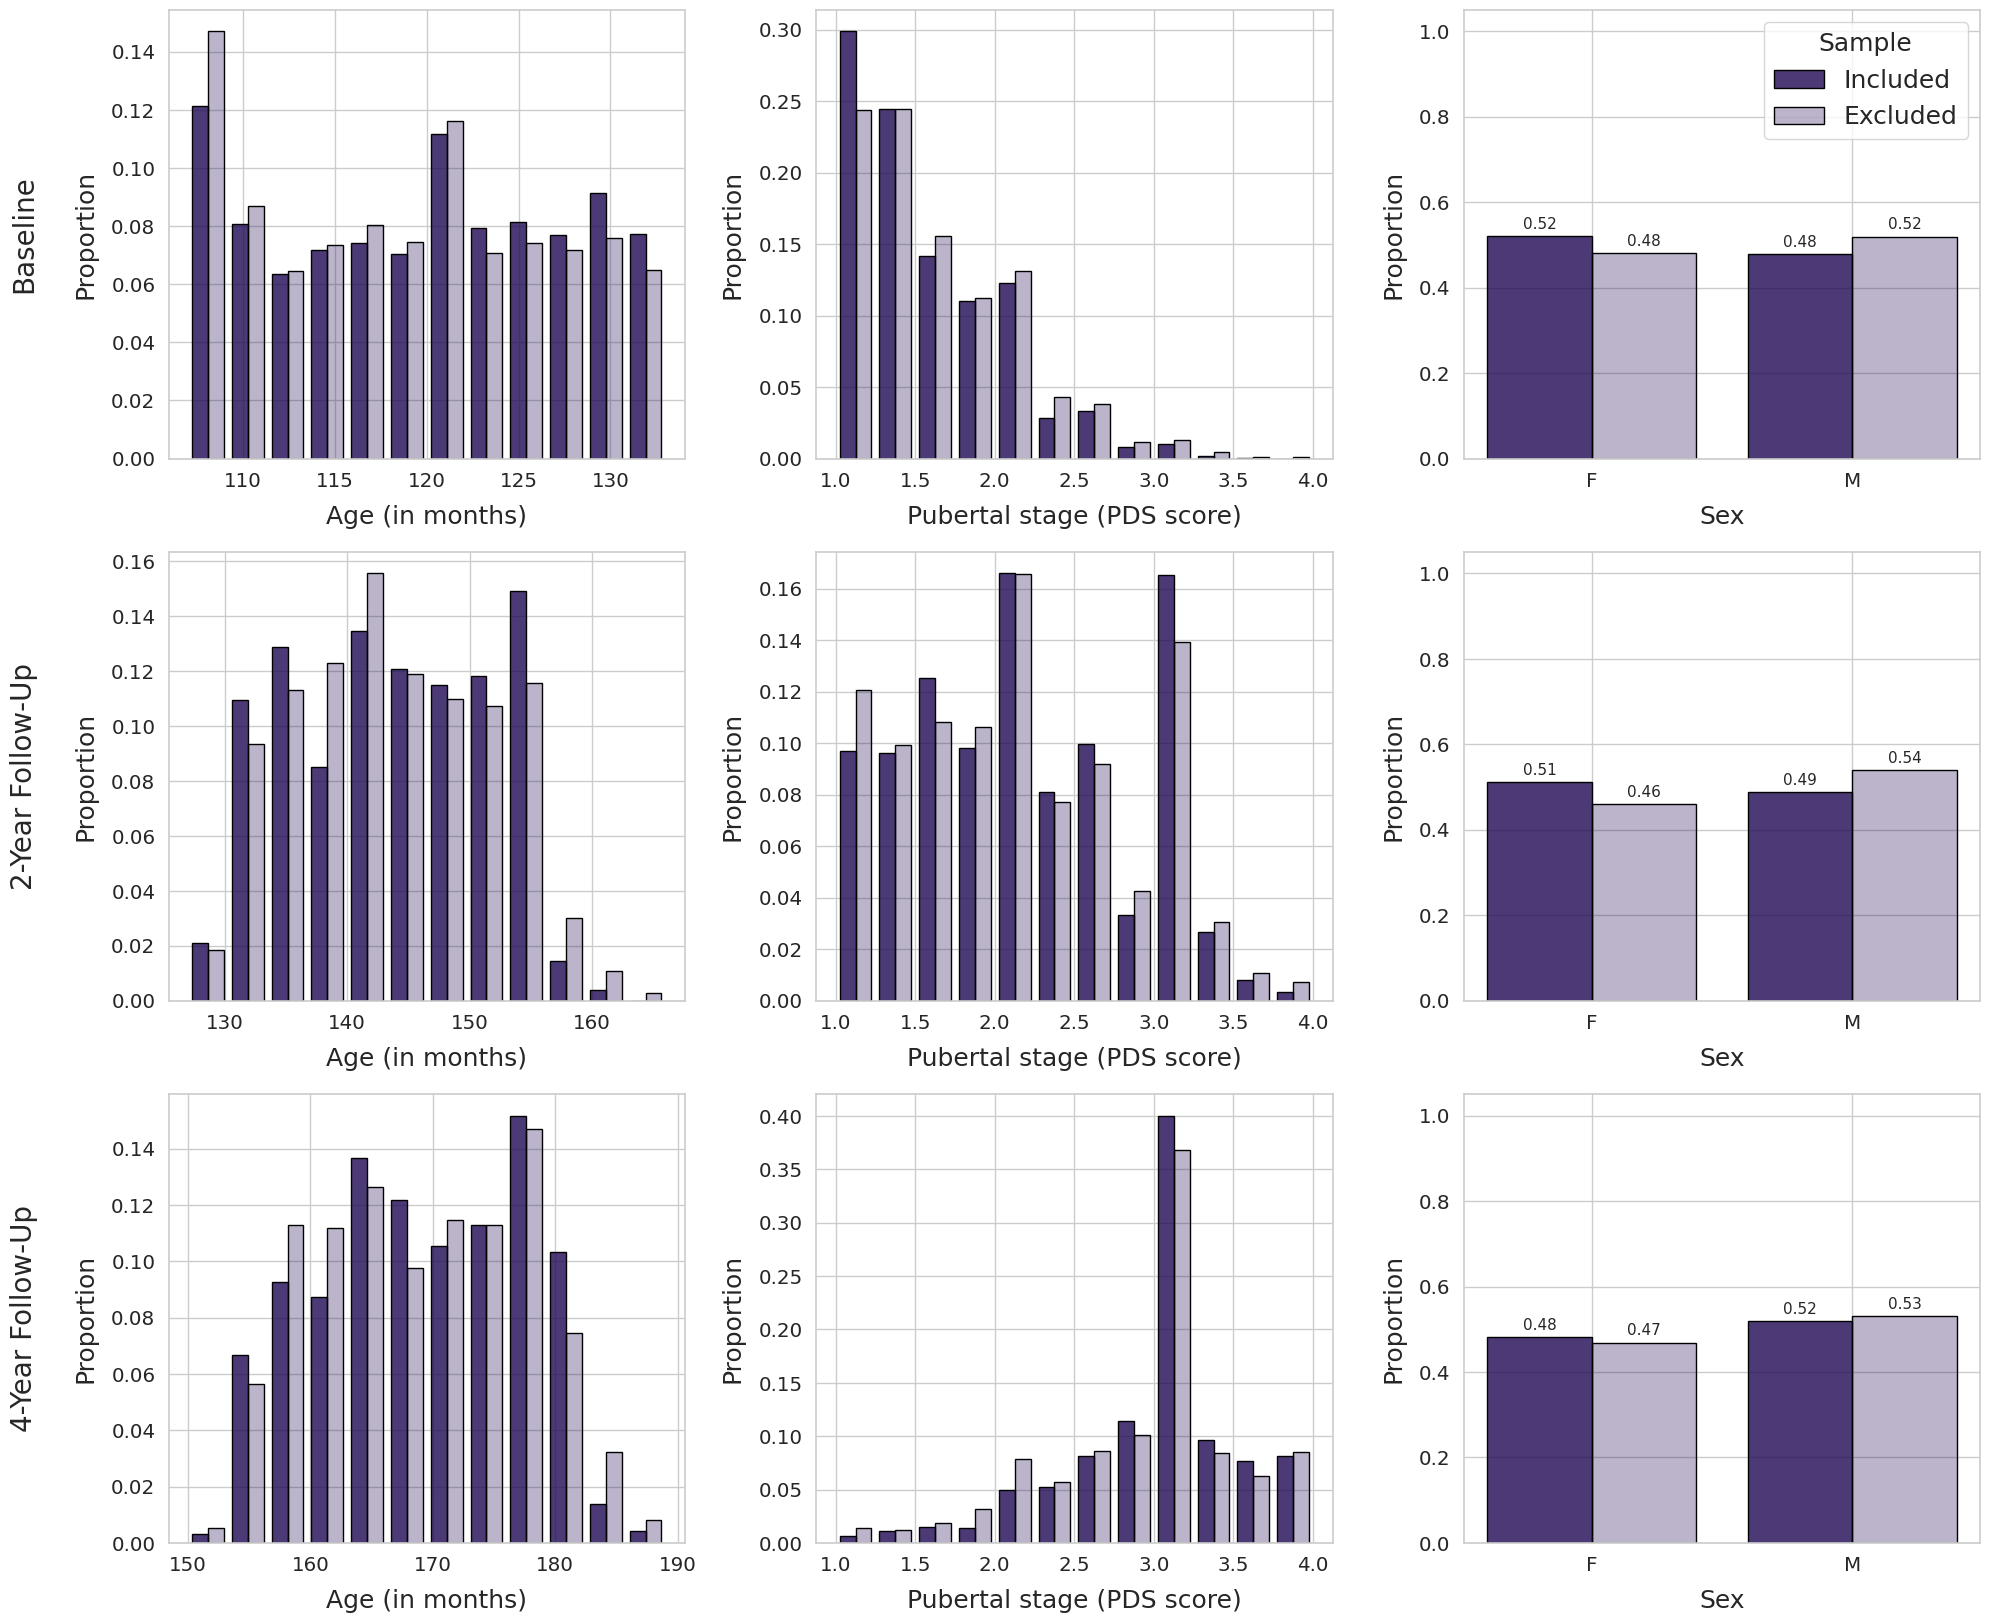

  timepoint     variable                  included                  excluded            test          stat             p    effect effect_type
0  Baseline   age_months             119.72 (7.53)             118.92 (7.49)  Mann-Whitney U  1.141072e+07  3.168415e-07  0.106288   Cohen's d
1  Baseline  pds_p_score               1.56 (0.46)               1.63 (0.50)  Mann-Whitney U  9.801416e+06  3.154950e-10 -0.135376   Cohen's d
2  Baseline          sex  {'F': 0.521, 'M': 0.479}  {'F': 0.481, 'M': 0.519}      Chi-square  1.493734e+01  1.111411e-04  0.039923  Cramér's V
3    2-year   age_months             143.60 (7.95)             143.63 (7.84)  Mann-Whitney U  3.527138e+06  8.693788e-01 -0.004655   Cohen's d
4    2-year  pds_p_score               2.16 (0.69)               2.13 (0.71)  Mann-Whitney U  3.585180e+06  1.397932e-01  0.040986   Cohen's d
5    2-year          sex  {'F': 0.513, 'M': 0.487}    {'F': 0.46, 'M': 0.54}      Chi-square  1.102075e+01  9.009777e-04  0.039879  Cramér's V

In [59]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf

ID = 'src_subject_id_fmt'

# (all-subject demographics, ABCD QC-passed subject list, your final sample)
timepoints = {
    'Baseline': (abcd_demo_baseline_all, sub_baseline_qc_val_relabelled, abcd_demo_baseline_clean),
    '2-year':   (abcd_demo_fu2y_all,     sub_fu2y_qc_val_relabelled,     abcd_demo_fu2y_clean),
    '4-year':   (abcd_demo_fu4y_all,     sub_fu4y_qc_val_relabelled,     abcd_demo_fu4y_clean),
}

def label_groups(demo_all, qc_subs, demo_final):
    qc_subs = set(qc_subs)
    final_ids = set(demo_final[ID])
    not_in_qc = final_ids - qc_subs
    if not_in_qc:
        print(f'  WARNING: {len(not_in_qc)} final-sample IDs not in QC list (check ID formatting)')
    df = demo_all[demo_all[ID].isin(qc_subs)].copy()
    df['group'] = np.where(df[ID].isin(final_ids), 'Included', 'Excluded')
    df['excluded'] = (df['group'] == 'Excluded').astype(int)
    return df

dfs = {}
for tp, (demo_all, qc_subs, demo_final) in timepoints.items():
    print(tp)
    dfs[tp] = label_groups(demo_all, qc_subs, demo_final)
    print(dfs[tp]['group'].value_counts().to_dict())

# ---------- Restrict to M/F only ----------
SEX_KEEP = ["M", "F"]

for tp, df in dfs.items():
    df["sex"] = df["sex"].astype(str)          # drop any unused categorical levels
    n_dropped = (~df["sex"].isin(SEX_KEEP)).sum()
    dfs[tp] = df[df["sex"].isin(SEX_KEEP)].copy()
    print(f"{tp}: dropped {n_dropped} participants not coded M/F; "
          f"{dfs[tp]['group'].value_counts().to_dict()}")

# ---------- Plots: rows = timepoints, cols = age / PDS / sex ----------
import matplotlib.colors as mcolors


# --- Style setup (matches your figures) ---
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2

group_order = ["Included", "Excluded"]
alpha_map = {"Included": 0.8, "Excluded": 0.3}
color_map = {g: mcolors.to_rgba("xkcd:dark indigo", alpha=a) for g, a in alpha_map.items()}
tp_labels = {"Baseline": "Baseline", "2-year": "2-Year Follow-Up", "4-year": "4-Year Follow-Up"}
sex_labels = None          # e.g. {1: "Male", 2: "Female"} or {"M": "Male", "F": "Female"}
AGE_BINS = 12              # adjust as needed
PDS_BINS = 12              # PDS takes discrete values; consider explicit edges, e.g. np.arange(0.875, 4.2, 0.25)
width = 0.4                # fraction of bin width per group

def grouped_hist(ax, df, var, bins):
    """Side-by-side bars of within-group proportions on shared bins."""
    edges = np.histogram_bin_edges(df[var].dropna(), bins=bins)
    centers = (edges[:-1] + edges[1:]) / 2
    w = (edges[1] - edges[0]) * width
    for i, g in enumerate(group_order):
        counts, _ = np.histogram(df.loc[df["group"] == g, var].dropna(), bins=edges)
        prop = counts / counts.sum() if counts.sum() else counts
        ax.bar(centers + (i - 0.5) * w, prop, width=w,
               color=color_map[g], edgecolor="black", label=g)

def grouped_sex(ax, df):
    """Side-by-side bars of sex proportions, annotated like your count labels."""
    levels = sorted(df["sex"].dropna().unique())
    x = np.arange(len(levels))
    for i, g in enumerate(group_order):
        p = (df.loc[df["group"] == g, "sex"]
               .value_counts(normalize=True).reindex(levels, fill_value=0))
        bars = ax.bar(x + (i - 0.5) * width, p.values, width=width,
                      color=color_map[g], edgecolor="black", label=g)
        for bar, val in zip(bars, p.values):
            ax.text(bar.get_x() + bar.get_width() / 2, val + 0.01, f"{val:.2f}",
                    ha="center", va="bottom", fontsize=11)
    ax.set_xticks(x)
    ax.set_xticklabels([sex_labels.get(l, l) for l in levels] if sex_labels else levels)
    ax.set_ylim(0, 1.05)

# --- Figure: rows = timepoints, cols = age / PDS / sex ---
fig, axes = plt.subplots(len(dfs), 3, figsize=(20, 5.5 * len(dfs)))

for r, (tp, df) in enumerate(dfs.items()):
    n = df["group"].value_counts()
    tp_name = tp_labels.get(tp, tp)

    grouped_hist(axes[r, 0], df, "age_months", AGE_BINS)
    grouped_hist(axes[r, 1], df, "pds_p_score", PDS_BINS)
    grouped_sex(axes[r, 2], df)

    axes[r, 0].set_xlabel("Age (in months)", fontsize=18, labelpad=10)
    axes[r, 1].set_xlabel("Pubertal stage (PDS score)", fontsize=18, labelpad=10)
    axes[r, 2].set_xlabel("Sex", fontsize=18, labelpad=10)
    for c in range(3):
        axes[r, c].set_ylabel("Proportion", fontsize=18, labelpad=10)

    # Row label (timepoint), sized independently
    axes[r, 0].text(-0.28, 0.5, tp_name,
                    transform=axes[r, 0].transAxes,
                    rotation=90, ha="center", va="center",
                    fontsize=20)
    
    #axes[r, 0].set_title(f"Included {n_label} = {n.get('Included', 0)}, "
    #                     f"Excluded {n_label} = {n.get('Excluded', 0)}",
    #                     fontsize=14, loc="left")


# --- Single legend, same style as your figures ---
axes[0, 2].legend(title="Sample", frameon=True, facecolor="white",
                  fontsize=18, title_fontsize=18, loc="upper right")

plt.tight_layout()

# --- Save figure ---
plt.savefig(resdir+'supplementary/exclusion_demographics.svg',
            format="svg", bbox_inches="tight", dpi=300)
plt.show()


# ---------- Group comparison table ----------
def cohens_d(a, b):
    pooled = np.sqrt(((len(a)-1)*a.var() + (len(b)-1)*b.var()) / (len(a)+len(b)-2))
    return (a.mean() - b.mean()) / pooled

rows = []
for tp, df in dfs.items():
    inc, exc = df[df.group == 'Included'], df[df.group == 'Excluded']
    for var in ['age_months', 'pds_p_score']:
        a, b = inc[var].dropna(), exc[var].dropna()
        U, p = stats.mannwhitneyu(a, b)
        rows.append(dict(timepoint=tp, variable=var,
                         included=f'{a.mean():.2f} ({a.std():.2f})',
                         excluded=f'{b.mean():.2f} ({b.std():.2f})',
                         test='Mann-Whitney U', stat=U, p=p,
                         effect=cohens_d(a, b), effect_type="Cohen's d"))
    ct = pd.crosstab(df['group'], df['sex'])
    chi2, p, _, _ = stats.chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    pct = pd.crosstab(df['group'], df['sex'], normalize='index').round(3)
    rows.append(dict(timepoint=tp, variable='sex',
                     included=pct.loc['Included'].to_dict(),
                     excluded=pct.loc['Excluded'].to_dict(),
                     test='Chi-square', stat=chi2, p=p,
                     effect=v, effect_type="Cramér's V"))

summary = pd.DataFrame(rows)
print(summary.to_string())

# ---------- Joint model: does any variable predict exclusion, controlling for the others? ----------
for tp, df in dfs.items():
    m = smf.logit('excluded ~ age_months + C(sex) + pds_p_score',
                  data=df.dropna(subset=['age_months', 'sex', 'pds_p_score'])).fit(disp=0)
    print(f'\n{tp}')
    print(pd.DataFrame({'OR': np.exp(m.params), 'p': m.pvalues,
                        'CI_low': np.exp(m.conf_int()[0]),
                        'CI_high': np.exp(m.conf_int()[1])}).round(3))

## 3 timepoints + across all

Baseline
{'Excluded': 5367, 'Included': 4007}
2-year
{'Excluded': 5696, 'Included': 1235}
4-year
{'Excluded': 1867, 'Included': 929}


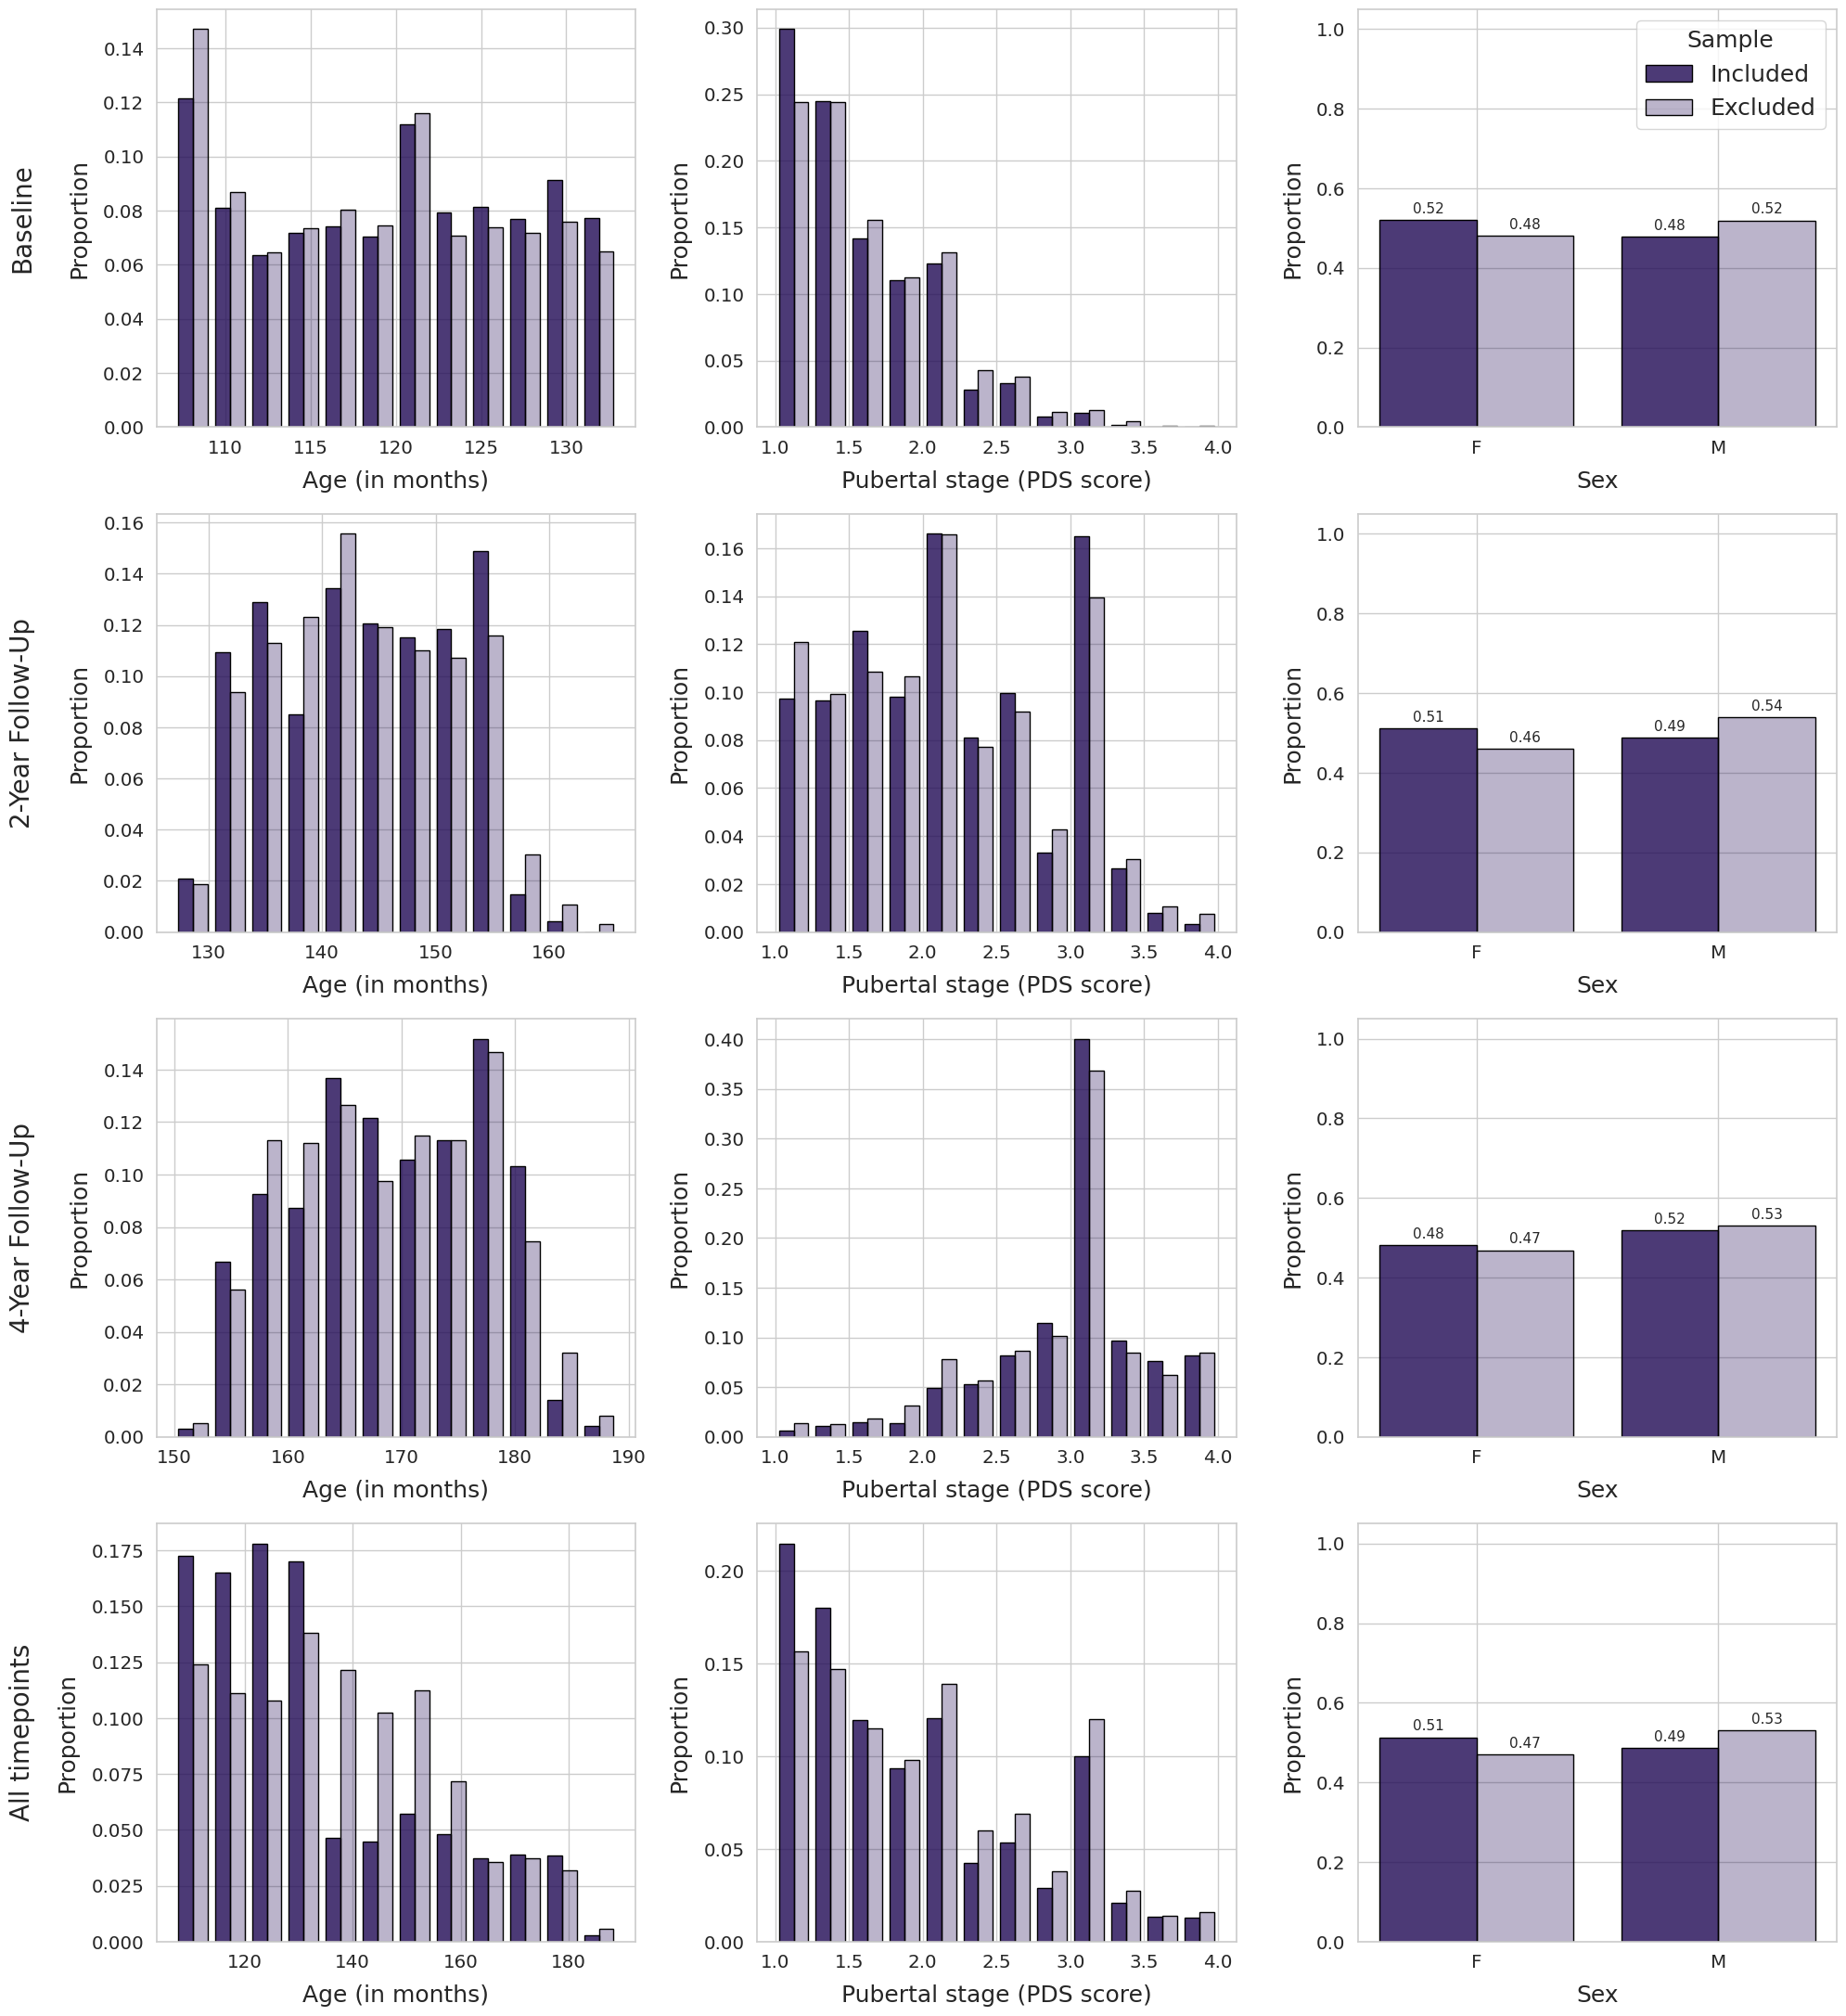

  timepoint     variable                                     included                                       excluded            test          stat             p    effect effect_type
0  Baseline   age_months                                119.72 (7.53)                                  118.92 (7.49)  Mann-Whitney U  1.141458e+07  3.212906e-07  0.106230   Cohen's d
1  Baseline  pds_p_score                                  1.56 (0.46)                                    1.63 (0.50)  Mann-Whitney U  9.801416e+06  3.154950e-10 -0.135376   Cohen's d
2  Baseline          sex  {'F': 0.521, 'Intersex-M': 0.0, 'M': 0.479}     {'F': 0.48, 'Intersex-M': 0.0, 'M': 0.519}      Chi-square  1.659351e+01  2.493247e-04  0.042073  Cramér's V
3    2-year   age_months                                143.60 (7.95)                                  143.64 (7.84)  Mann-Whitney U  3.527219e+06  8.760271e-01 -0.004908   Cohen's d
4    2-year  pds_p_score                                  2.16 (0.69)                

In [58]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf

ID = 'src_subject_id_fmt'

# (all-subject demographics, ABCD QC-passed subject list, your final sample)
timepoints = {
    'Baseline': (abcd_demo_baseline_all, sub_baseline_qc_val_relabelled, abcd_demo_baseline_clean),
    '2-year':   (abcd_demo_fu2y_all,     sub_fu2y_qc_val_relabelled,     abcd_demo_fu2y_clean),
    '4-year':   (abcd_demo_fu4y_all,     sub_fu4y_qc_val_relabelled,     abcd_demo_fu4y_clean),
}

def label_groups(demo_all, qc_subs, demo_final):
    qc_subs = set(qc_subs)
    final_ids = set(demo_final[ID])
    not_in_qc = final_ids - qc_subs
    if not_in_qc:
        print(f'  WARNING: {len(not_in_qc)} final-sample IDs not in QC list (check ID formatting)')
    df = demo_all[demo_all[ID].isin(qc_subs)].copy()
    df['group'] = np.where(df[ID].isin(final_ids), 'Included', 'Excluded')
    df['excluded'] = (df['group'] == 'Excluded').astype(int)
    return df

dfs = {}
for tp, (demo_all, qc_subs, demo_final) in timepoints.items():
    print(tp)
    dfs[tp] = label_groups(demo_all, qc_subs, demo_final)
    print(dfs[tp]['group'].value_counts().to_dict())

# ---------- Plots: rows = timepoints, cols = age / PDS / sex ----------
import matplotlib.colors as mcolors

# --- Style setup (matches your figures) ---
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2

group_order = ["Included", "Excluded"]
alpha_map = {"Included": 0.8, "Excluded": 0.3}
color_map = {g: mcolors.to_rgba("xkcd:dark indigo", alpha=a) for g, a in alpha_map.items()}
tp_labels = {"Baseline": "Baseline", "2-year": "2-Year Follow-Up", "4-year": "4-Year Follow-Up"}
sex_labels = None          # e.g. {1: "Male", 2: "Female"} or {"M": "Male", "F": "Female"}
AGE_BINS = 12              # adjust as needed
PDS_BINS = 12              # PDS takes discrete values; consider explicit edges, e.g. np.arange(0.875, 4.2, 0.25)
width = 0.4                # fraction of bin width per group

def grouped_hist(ax, df, var, bins):
    """Side-by-side bars of within-group proportions on shared bins."""
    edges = np.histogram_bin_edges(df[var].dropna(), bins=bins)
    centers = (edges[:-1] + edges[1:]) / 2
    w = (edges[1] - edges[0]) * width
    for i, g in enumerate(group_order):
        counts, _ = np.histogram(df.loc[df["group"] == g, var].dropna(), bins=edges)
        prop = counts / counts.sum() if counts.sum() else counts
        ax.bar(centers + (i - 0.5) * w, prop, width=w,
               color=color_map[g], edgecolor="black", label=g)

def grouped_sex(ax, df):
    """Side-by-side bars of sex proportions, annotated like your count labels."""
    levels = sorted(df["sex"].dropna().unique())
    x = np.arange(len(levels))
    for i, g in enumerate(group_order):
        p = (df.loc[df["group"] == g, "sex"]
               .value_counts(normalize=True).reindex(levels, fill_value=0))
        bars = ax.bar(x + (i - 0.5) * width, p.values, width=width,
                      color=color_map[g], edgecolor="black", label=g)
        for bar, val in zip(bars, p.values):
            ax.text(bar.get_x() + bar.get_width() / 2, val + 0.01, f"{val:.2f}",
                    ha="center", va="bottom", fontsize=11)
    ax.set_xticks(x)
    ax.set_xticklabels([sex_labels.get(l, l) for l in levels] if sex_labels else levels)
    ax.set_ylim(0, 1.05)

# --- Figure: rows = timepoints, cols = age / PDS / sex ---
# --- Add pooled data across all timepoints ---
plot_dfs = dict(dfs)
plot_dfs["All"] = pd.concat(
    [df.assign(timepoint=tp) for tp, df in dfs.items()], ignore_index=True
)
tp_labels["All"] = "All timepoints"

SEX_KEEP = ["M", "F"]   # match your coding

plot_dfs = {tp: df[df["sex"].isin(SEX_KEEP)].copy() for tp, df in plot_dfs.items()}
for tp, df in plot_dfs.items():
    df["sex"] = df["sex"].astype(str).astype("category").cat.set_categories(
        [str(s) for s in SEX_KEEP])

# --- Figure: rows = timepoints + pooled, cols = age / PDS / sex ---
fig, axes = plt.subplots(len(plot_dfs), 3, figsize=(20, 5.5 * len(plot_dfs)))
age_ticks = np.arange(108, 181, 12)   # 108, 120, ..., 180

for r, (tp, df) in enumerate(plot_dfs.items()):
    n = df["group"].value_counts()
    tp_name = tp_labels.get(tp, tp)

    grouped_hist(axes[r, 0], df, "age_months", AGE_BINS)
    grouped_hist(axes[r, 1], df, "pds_p_score", PDS_BINS)
    grouped_sex(axes[r, 2], df)

    axes[r, 0].set_xlabel("Age (in months)", fontsize=18, labelpad=10)
    axes[r, 1].set_xlabel("Pubertal stage (PDS score)", fontsize=18, labelpad=10)
    axes[r, 2].set_xlabel("Sex", fontsize=18, labelpad=10)
    for c in range(3):
        axes[r, c].set_ylabel("Proportion", fontsize=18, labelpad=10)

    # Row label (timepoint), sized independently
    axes[r, 0].text(-0.28, 0.5, tp_name,
                    transform=axes[r, 0].transAxes,
                    rotation=90, ha="center", va="center",
                    fontsize=20)
    
    #axes[r, 0].set_title(f"Included {n_label} = {n.get('Included', 0)}, "
    #                     f"Excluded {n_label} = {n.get('Excluded', 0)}",
    #                     fontsize=14, loc="left")

# --- Single legend, same style as your figures ---
axes[0, 2].legend(title="Sample", frameon=True, facecolor="white",
                  fontsize=18, title_fontsize=18, loc="upper right")

plt.tight_layout()

# --- Save figure ---
plt.savefig(resdir+'supplementary/exclusion_demographics_with_total_across_timepoints.svg',
            format="svg", bbox_inches="tight", dpi=300)
plt.show()


# ---------- Group comparison table ----------
def cohens_d(a, b):
    pooled = np.sqrt(((len(a)-1)*a.var() + (len(b)-1)*b.var()) / (len(a)+len(b)-2))
    return (a.mean() - b.mean()) / pooled

rows = []
for tp, df in dfs.items():
    inc, exc = df[df.group == 'Included'], df[df.group == 'Excluded']
    for var in ['age_months', 'pds_p_score']:
        a, b = inc[var].dropna(), exc[var].dropna()
        U, p = stats.mannwhitneyu(a, b)
        rows.append(dict(timepoint=tp, variable=var,
                         included=f'{a.mean():.2f} ({a.std():.2f})',
                         excluded=f'{b.mean():.2f} ({b.std():.2f})',
                         test='Mann-Whitney U', stat=U, p=p,
                         effect=cohens_d(a, b), effect_type="Cohen's d"))
    ct = pd.crosstab(df['group'], df['sex'])
    chi2, p, _, _ = stats.chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    pct = pd.crosstab(df['group'], df['sex'], normalize='index').round(3)
    rows.append(dict(timepoint=tp, variable='sex',
                     included=pct.loc['Included'].to_dict(),
                     excluded=pct.loc['Excluded'].to_dict(),
                     test='Chi-square', stat=chi2, p=p,
                     effect=v, effect_type="Cramér's V"))

summary = pd.DataFrame(rows)
print(summary.to_string())

# ---------- Joint model: does any variable predict exclusion, controlling for the others? ----------
for tp, df in dfs.items():
    m = smf.logit('excluded ~ age_months + C(sex) + pds_p_score',
                  data=df.dropna(subset=['age_months', 'sex', 'pds_p_score'])).fit(disp=0)
    print(f'\n{tp}')
    print(pd.DataFrame({'OR': np.exp(m.params), 'p': m.pvalues,
                        'CI_low': np.exp(m.conf_int()[0]),
                        'CI_high': np.exp(m.conf_int()[1])}).round(3))